Identificação de pontes e vertices de articulação

---

Bibliotecas

In [45]:
import cv2

import matplotlib.pyplot as plt
import networkx          as nx
import numpy             as np


---

Carregando a imagem

In [46]:
josefran_image = cv2.imread("../assets/josefran.jpg")
josefran_image = cv2.cvtColor(josefran_image, cv2.COLOR_BGR2GRAY)

josefran_image.shape

(640, 640)

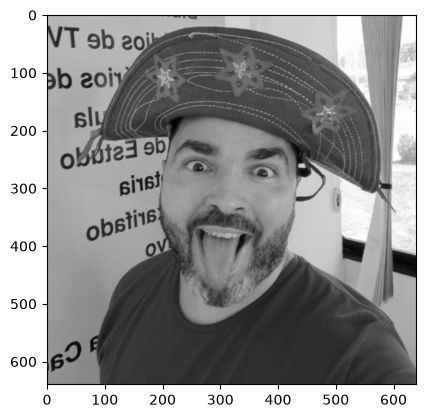

In [47]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

Redimensionando para $64\times64$

In [48]:
josefran_image = cv2.resize(josefran_image, (64, 64), cv2.INTER_LINEAR)
josefran_image.shape

(64, 64)

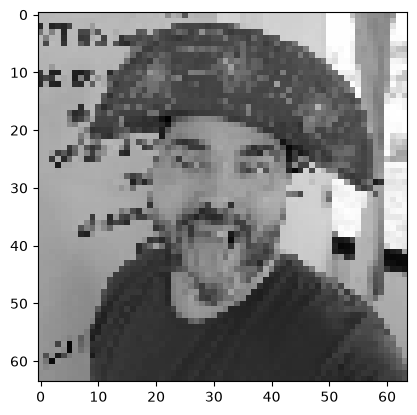

In [49]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

---

Gerando um grafo da imagem exemplo

In [50]:
def construir_grafo_imagem(matriz_pixels, vizinhanca=4, limiar=10):
    altura, largura = matriz_pixels.shape
    grafo           = { (i, j): [] for i in range(altura) for j in range(largura) }
    
    # Definir deslocamentos com base na vizinhança
    if vizinhanca == 4:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    elif vizinhanca == 8:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1), 
                    (-1, -1), (-1, 1), (1, -1), (1, 1)]
    else:
        raise ValueError("A vizinhança deve ser 4 ou 8.")

    for i in range(altura):
        for j in range(largura):
            u = (i, j)
            intensidade_u = matriz_pixels[i, j]
            
            for di, dj in direcoes:
                ni, nj = i + di, j + dj
                
                if 0 <= ni < altura and 0 <= nj < largura:
                    v = (ni, nj)
                    intensidade_v = matriz_pixels[ni, nj]
                    
                    if abs(int(intensidade_u) - int(intensidade_v)) <= limiar:
                        grafo[u].append(v)
                        
    return grafo

In [51]:
josefran_graph = construir_grafo_imagem(josefran_image)

---

Identificação de pontes e articulações

In [52]:
def encontrar_pontes_e_articulacoes(grafo):
    """
    Identifica pontes e vértices de articulação em um grafo não direcionado
    representado como dicionário {vertice: [vizinhos]} usando DFS e low[].
    """
    tin = {}           # Tempo de descoberta de cada vértice
    low = {}           # Menor tempo de descoberta alcançável na subárvore
    visitado = set()
    pontes = set()     # Armazena arestas críticas como tuplas ordenadas (min_v, max_v)
    articulacoes = set()
    timer = 0

    for inicio in grafo:
        if inicio in visitado:
            continue

        # Pilha de execução: [u, pai, iterador_vizinhos, filhos_dfs]
        visitado.add(inicio)
        timer += 1
        tin[inicio] = low[inicio] = timer
        pilha = [[inicio, None, iter(grafo.get(inicio, [])), 0]]

        while pilha:
            u, pai, vizinhos, _ = pilha[-1]

            try:
                v = next(vizinhos)

                # Ignora a aresta direta para o pai na árvore DFS
                if v == pai:
                    continue

                if v in visitado:
                    # Back-edge (aresta de retorno): atualiza low[u] com tin[v]
                    if tin[v] < low[u]:
                        low[u] = tin[v]
                else:
                    # Tree-edge (aresta de árvore): incrementa filhos de u e desce em v
                    pilha[-1][3] += 1
                    visitado.add(v)
                    timer += 1
                    tin[v] = low[v] = timer
                    pilha.append([v, u, iter(grafo.get(v, [])), 0])

            except StopIteration:
                # Todos os vizinhos de u foram processados; faz o backtrack
                pilha.pop()

                if pilha:
                    _, _, _, filhos_dfs = (u, pai, None, None)
                    # Recupera referência atualizada do topo da pilha (que é o pai de u)
                    frame_pai = pilha[-1]
                    p = frame_pai[0]
                    avo = frame_pai[1]
                    num_filhos_p = frame_pai[3]

                    # Propaga low[u] para o pai p
                    if low[u] < low[p]:
                        low[p] = low[u]

                    # Condição de ponte: não há caminho de volta de v (aqui u) para p ou seus ancestrais
                    if low[u] > tin[p]:
                        aresta = tuple(sorted((p, u)))
                        pontes.add(aresta)

                    # Condição de vértice de articulação:
                    # 1) p não é a raiz da árvore DFS e algum filho u tem low[u] >= tin[p]
                    if avo is not None and low[u] >= tin[p]:
                        articulacoes.add(p)

        # 2) Caso especial da raiz da árvore DFS: é articulação se tiver 2 ou mais filhos na DFS
        if filhos_dfs_raiz := (tin[inicio] == 1 and ...):
            pass

    return pontes, articulacoes

In [53]:
pontes, articulacoes = encontrar_pontes_e_articulacoes(josefran_graph)

print(f"Total de vértices: {len(josefran_graph)}")
print(f"Total de pontes encontradas: {len(pontes)}")
print(f"Total de vértices de articulação encontrados: {len(articulacoes)}")

# Exemplo: exibir os primeiros 10 resultados de cada
print("Primeiras pontes:", list(pontes)[:10])
print("Primeiras articulações:", list(articulacoes)[:10])

Total de vértices: 4096
Total de pontes encontradas: 749
Total de vértices de articulação encontrados: 552
Primeiras pontes: [((12, 36), (13, 36)), ((28, 47), (29, 47)), ((11, 44), (12, 44)), ((5, 32), (6, 32)), ((36, 22), (37, 22)), ((13, 61), (13, 62)), ((18, 49), (19, 49)), ((11, 35), (11, 36)), ((11, 53), (11, 54)), ((37, 26), (38, 26))]
Primeiras articulações: [(15, 21), (26, 21), (38, 23), (47, 53), (49, 23), (26, 30), (7, 35), (48, 36), (18, 44), (11, 5)]


---

Visualização das pontes e articulações

In [54]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np


def plotar_pontes_e_articulacoes(matriz_pixels, grafo, pontes, articulacoes, mostrar_arestas_base=True):
    """
    Cria uma figura com dois subplots:
      1) Visualização das pontes (arestas críticas).
      2) Visualização dos vértices de articulação (nós críticos).

    Parâmetros:
      matriz_pixels: matriz 2D em escala de cinza (ex.: 64x64).
      grafo: dicionário { (i, j): [(ni, nj), ...] }.
      pontes: conjunto/coleção de arestas ((i1, j1), (i2, j2)).
      articulacoes: conjunto/coleção de vértices (i, j).
      mostrar_arestas_base: se True, exibe as arestas do grafo com baixa opacidade ao fundo.
    """
    altura, largura = matriz_pixels.shape

    # Converte o dicionário de adjacência para um grafo do NetworkX
    G = nx.Graph()
    for i in range(altura):
        for j in range(largura):
            u = (i, j)
            G.add_node(u)
            for v in grafo.get(u, []):
                if u < v:  # Evita duplicar arestas não direcionadas
                    G.add_edge(u, v)

    # No imshow, o eixo x é a coluna (j) e o eixo y é a linha (i), com origem no topo (0..altura)
    pos = {u: (u[1], u[0]) for u in G.nodes()}

    # Normaliza o conjunto de pontes como pares ordenados
    pontes_set = {tuple(sorted((u, v))) for (u, v) in pontes}
    arestas_pontes = [e for e in G.edges() if tuple(sorted(e)) in pontes_set]
    arestas_normais = [e for e in G.edges() if tuple(sorted(e)) not in pontes_set]

    # Vértices envolvidos em pontes (para opcionalmente realçar extremidades)
    nos_pontes = sorted({u for e in arestas_pontes for u in e})
    articulacoes_lista = [v for v in articulacoes if v in G]

    fig, axes = plt.subplots(1, 2, figsize=(15, 7), dpi=120)

    # --- SUBPLOT 1: PONTES ---
    ax1 = axes[0]
    ax1.imshow(matriz_pixels, cmap="gray", vmin=0, vmax=255)

    if mostrar_arestas_base and arestas_normais:
        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=arestas_normais,
            ax=ax1,
            edge_color="cyan",
            width=0.35,
            alpha=0.18,
        )

    if nos_pontes:
        nx.draw_networkx_nodes(
            G,
            pos,
            nodelist=nos_pontes,
            ax=ax1,
            node_color="gold",
            node_size=14,
            alpha=0.85,
            linewidths=0.4,
            edgecolors="black",
        )

    if arestas_pontes:
        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=arestas_pontes,
            ax=ax1,
            edge_color="#FF5500",
            width=1.8,
            alpha=0.95,
        )

    ax1.set_title(f"Pontes no Grafo ({len(arestas_pontes)} arestas)", fontsize=12, fontweight="bold")
    ax1.set_xlim(-0.5, largura - 0.5)
    ax1.set_ylim(altura - 0.5, -0.5)
    ax1.axis("off")

    # --- SUBPLOT 2: VÉRTICES DE ARTICULAÇÃO ---
    ax2 = axes[1]
    ax2.imshow(matriz_pixels, cmap="gray", vmin=0, vmax=255)

    if mostrar_arestas_base and G.edges():
        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=list(G.edges()),
            ax=ax2,
            edge_color="lightgray",
            width=0.3,
            alpha=0.18,
        )

    if articulacoes_lista:
        nx.draw_networkx_nodes(
            G,
            pos,
            nodelist=articulacoes_lista,
            ax=ax2,
            node_color="#FF1E1E",
            node_size=24,
            alpha=0.95,
            linewidths=0.5,
            edgecolors="yellow",
        )

    ax2.set_title(
        f"Vértices de Articulação ({len(articulacoes_lista)} vértices)",
        fontsize=12,
        fontweight="bold",
    )
    ax2.set_xlim(-0.5, largura - 0.5)
    ax2.set_ylim(altura - 0.5, -0.5)
    ax2.axis("off")

    plt.suptitle(
        "Estruturas Críticas Identificadas via DFS e low[]",
        fontsize=14,
        fontweight="bold",
        y=0.98,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

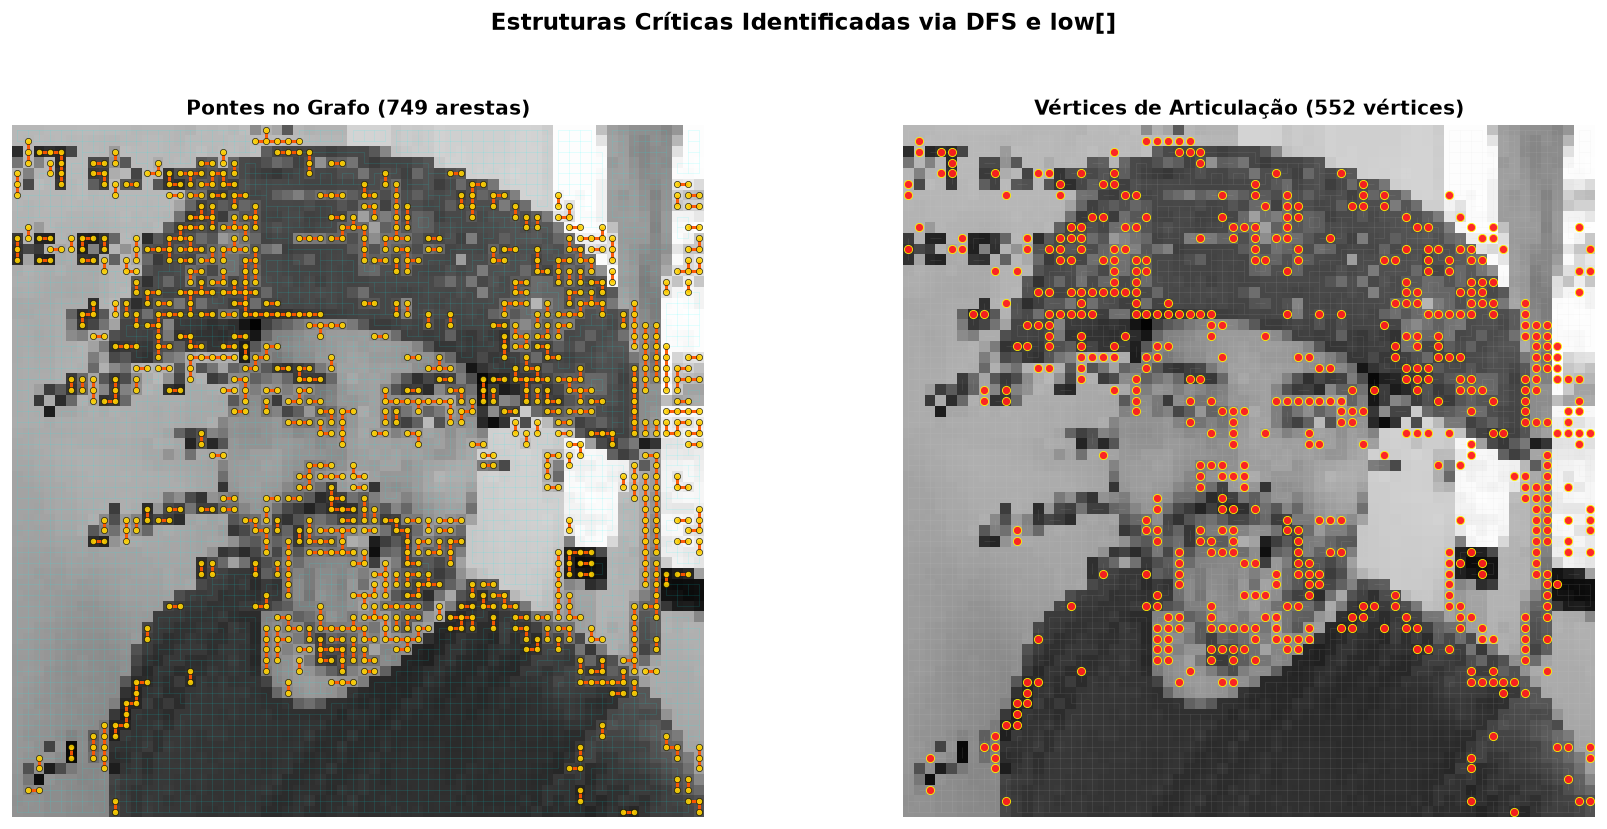

In [55]:
pontes, articulacoes = encontrar_pontes_e_articulacoes(josefran_graph)

plotar_pontes_e_articulacoes(
    matriz_pixels=josefran_image,
    grafo=josefran_graph,
    pontes=pontes,
    articulacoes=articulacoes,
    mostrar_arestas_base=True,  # Mude para False se quiser ver apenas a imagem e as estruturas críticas
)

---

In [56]:
def construir_grafo_imagem(matriz_pixels, vizinhanca=4, limiar=10):
    altura, largura = matriz_pixels.shape
    grafo = {(i, j): [] for i in range(altura) for j in range(largura)}

    if vizinhanca == 4:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    elif vizinhanca == 8:
        direcoes = [
            (-1, 0), (1, 0), (0, -1), (0, 1),
            (-1, -1), (-1, 1), (1, -1), (1, 1),
        ]
    else:
        raise ValueError("A vizinhança deve ser 4 ou 8.")

    for i in range(altura):
        for j in range(largura):
            u = (i, j)
            intensidade_u = matriz_pixels[i, j]
            for di, dj in direcoes:
                ni, nj = i + di, j + dj
                if 0 <= ni < altura and 0 <= nj < largura:
                    v = (ni, nj)
                    intensidade_v = matriz_pixels[ni, nj]
                    if abs(int(intensidade_u) - int(intensidade_v)) <= limiar:
                        grafo[u].append(v)

    return grafo

In [57]:
# ==========================================
# IMAGEM ARTIFICIAL 1: Faixa estreita (6x9)
# ==========================================
img_1 = np.array([
    [ 50,  50,  50, 250, 125, 250, 200, 200, 200],
    [ 50,  50,  50, 250, 125, 250, 200, 200, 200],
    [ 50,  50,  50, 250, 125, 250, 200, 200, 200],
    [ 50,  50,  50, 250, 125, 250, 200, 200, 200],
    [ 50,  50,  50, 250, 125, 250, 200, 200, 200],
    [ 50,  50,  50, 250, 125, 250, 200, 200, 200],
], dtype=np.uint8)

grafo_1 = construir_grafo_imagem(img_1, vizinhanca=4, limiar=10)
pontes_1, art_1 = encontrar_pontes_e_articulacoes(grafo_1)

plotar_pontes_e_articulacoes(
    matriz_pixels=img_1,
    grafo=grafo_1,
    pontes=pontes_1,
    articulacoes=art_1,
    titulo="Imagem Artificial 1 (6x9, vizinhança=4, limiar=10) — Faixa Vertical de Transição",
)

TypeError: plotar_pontes_e_articulacoes() got an unexpected keyword argument 'titulo'

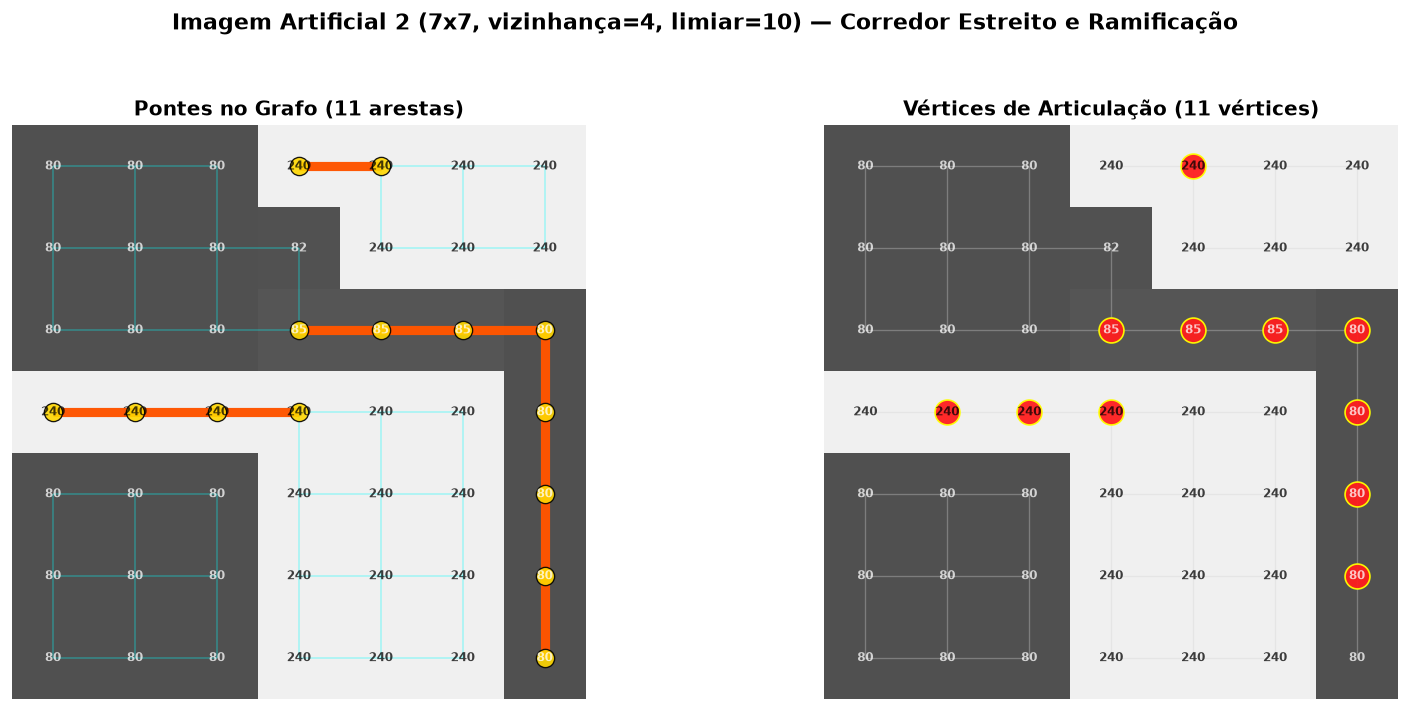

In [ ]:
# ==========================================
# IMAGEM ARTIFICIAL 2: Corredor e apêndice (7x7)
# ==========================================
img_2 = np.array([
    [ 80,  80,  80, 240, 240, 240, 240],
    [ 80,  80,  80,  82, 240, 240, 240],
    [ 80,  80,  80,  85,  85,  85,  80],
    [240, 240, 240, 240, 240, 240,  80],
    [ 80,  80,  80, 240, 240, 240,  80],
    [ 80,  80,  80, 240, 240, 240,  80],
    [ 80,  80,  80, 240, 240, 240,  80],
], dtype=np.uint8)

grafo_2 = construir_grafo_imagem(img_2, vizinhanca=4, limiar=10)
pontes_2, art_2 = encontrar_pontes_e_articulacoes(grafo_2)

plotar_pontes_e_articulacoes(
    matriz_pixels=img_2,
    grafo=grafo_2,
    pontes=pontes_2,
    articulacoes=art_2,
    titulo="Imagem Artificial 2 (7x7, vizinhança=4, limiar=10) — Corredor Estreito e Ramificação",
)